<a href="https://colab.research.google.com/github/Aryanshh/CSET343/blob/main/Lab6_1758.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kagglehub opencv-python scikit-image scikit-learn seaborn tqdm

In [2]:
import os
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import kagglehub
from tqdm.notebook import tqdm

# Download dataset
path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

print("Dataset downloaded at:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset downloaded at: /kaggle/input/chest-xray-pneumonia


Total images: 11712

Class distribution:
label
PNEUMONIA    8546
NORMAL       3166
Name: count, dtype: int64


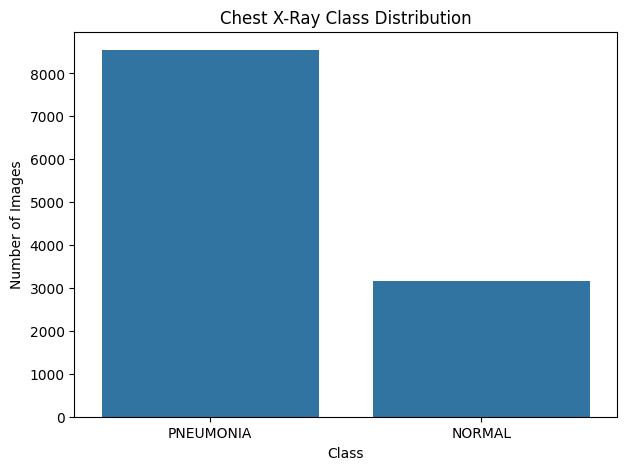

In [3]:
# Find all image files
image_paths = glob.glob(path + "/**/*.jpeg", recursive=True)

# Extract labels from folder names
data = []

for img_path in image_paths:
    label = os.path.basename(os.path.dirname(img_path))

    if label in ["NORMAL", "PNEUMONIA"]:
        data.append((img_path, label))

df = pd.DataFrame(data, columns=["image_path", "label"])

print("Total images:", len(df))
print("\nClass distribution:")
print(df["label"].value_counts())

# Plot class distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="label")
plt.title("Chest X-Ray Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

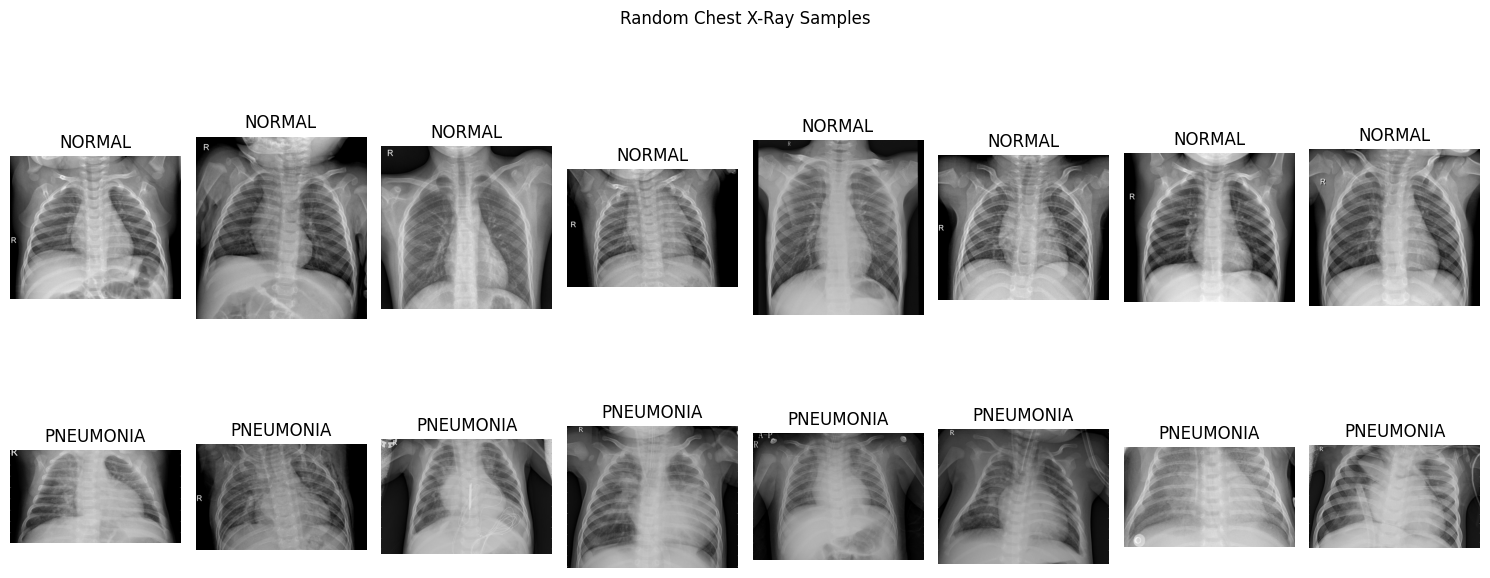

In [4]:
classes = ["NORMAL", "PNEUMONIA"]

plt.figure(figsize=(15, 7))

for i, cls in enumerate(classes):
    samples = df[df["label"] == cls].sample(
        n=min(8, len(df[df["label"] == cls])),
        random_state=42
    )

    for j, (_, row) in enumerate(samples.iterrows()):
        img = cv2.imread(row["image_path"], cv2.IMREAD_GRAYSCALE)

        plt.subplot(2, 8, i * 8 + j + 1)
        plt.imshow(img, cmap="gray")
        plt.title(cls)
        plt.axis("off")

plt.suptitle("Random Chest X-Ray Samples")
plt.tight_layout()
plt.show()

In [5]:
IMG_SIZE = 128

def preprocess_image(image_path):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

    img = img.astype("float32") / 255.0

    return img

# Encode labels
df["label_encoded"] = df["label"].map({
    "NORMAL": 0,
    "PNEUMONIA": 1
})

print(df.head())

                                          image_path      label  label_encoded
0  /kaggle/input/chest-xray-pneumonia/chest_xray/...  PNEUMONIA              1
1  /kaggle/input/chest-xray-pneumonia/chest_xray/...  PNEUMONIA              1
2  /kaggle/input/chest-xray-pneumonia/chest_xray/...  PNEUMONIA              1
3  /kaggle/input/chest-xray-pneumonia/chest_xray/...  PNEUMONIA              1
4  /kaggle/input/chest-xray-pneumonia/chest_xray/...  PNEUMONIA              1


In [6]:
from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

def extract_features(image_path):

    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (128, 128))

    # HOG Features
    hog_features = hog(
        img,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )

    # LBP Features
    lbp = local_binary_pattern(
        img,
        P=8,
        R=1,
        method="uniform"
    )

    lbp_hist, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(0, 11),
        range=(0, 10)
    )

    lbp_hist = lbp_hist.astype("float32")
    lbp_hist /= (lbp_hist.sum() + 1e-7)

    # GLCM Features
    glcm = graycomatrix(
        img,
        distances=[1],
        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
        levels=256,
        symmetric=True,
        normed=True
    )

    properties = [
        "contrast",
        "dissimilarity",
        "homogeneity",
        "energy",
        "correlation",
        "ASM"
    ]

    glcm_features = []

    for prop in properties:
        glcm_features.extend(
            graycoprops(glcm, prop).flatten()
        )

    # Combine all features
    features = np.concatenate([
        hog_features,
        lbp_hist,
        glcm_features
    ])

    return features

In [7]:
X_features = []

for img_path in tqdm(df["image_path"]):
    features = extract_features(img_path)
    X_features.append(features)

X_features = np.array(X_features)

y = df["label_encoded"].values

print("Feature matrix shape:", X_features.shape)
print("Labels shape:", y.shape)

  0%|          | 0/11712 [00:00<?, ?it/s]

Feature matrix shape: (11712, 1798)
Labels shape: (11712,)


In [8]:
from sklearn.model_selection import train_test_split

# First split: 70% training and 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X_features,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation and 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 8198
Validation samples: 1757
Testing samples: 1757


In [9]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(probability=True, random_state=42))
])

param_grid = {
    "classifier__C": [0.1, 1, 10],
    "classifier__kernel": ["linear", "rbf"],
    "classifier__gamma": ["scale", "auto"]
}

grid_search = GridSearchCV(
    svm_pipeline,
    param_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

best_svm = grid_search.best_estimator_

print("Best SVM Parameters:", grid_search.best_params_)
print("Best Cross Validation F1:", grid_search.best_score_)


Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best SVM Parameters: {'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}
Best Cross Validation F1: 0.9873356313425253


In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

svm_pred = best_svm.predict(X_test)
svm_prob = best_svm.predict_proba(X_test)[:, 1]

print("SVM Evaluation")
print("------------------------")

print("Accuracy:", accuracy_score(y_test, svm_pred))
print("Precision:", precision_score(y_test, svm_pred))
print("Recall:", recall_score(y_test, svm_pred))
print("F1 Score:", f1_score(y_test, svm_pred))
print("AUROC:", roc_auc_score(y_test, svm_prob))

print("\nClassification Report:")
print(classification_report(
    y_test,
    svm_pred,
    target_names=["NORMAL", "PNEUMONIA"]
))

SVM Evaluation
------------------------
Accuracy: 0.9903244166192373
Precision: 0.9922178988326849
Recall: 0.9945397815912637
F1 Score: 0.9933774834437086
AUROC: 0.9989752853272026

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.99      0.98      0.98       475
   PNEUMONIA       0.99      0.99      0.99      1282

    accuracy                           0.99      1757
   macro avg       0.99      0.99      0.99      1757
weighted avg       0.99      0.99      0.99      1757



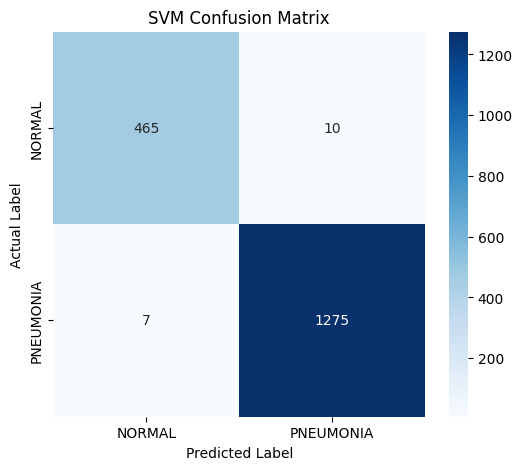

In [11]:
cm = confusion_matrix(y_test, svm_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SVM Confusion Matrix")
plt.show()

In [12]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproduce the same stratified split for image paths
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    df["image_path"].values,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

BATCH_SIZE = 32
IMG_SIZE = 128

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=1)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0

    return image, tf.cast(label, tf.float32)

def create_dataset(paths, labels, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_ds = create_dataset(
    train_paths, train_labels, training=True
)

val_ds = create_dataset(
    val_paths, val_labels
)

test_ds = create_dataset(
    test_paths, test_labels
)

print("CNN datasets prepared successfully!")

CNN datasets prepared successfully!


In [13]:
def build_cnn(learning_rate=0.001):

    model = keras.Sequential([

        layers.Input(shape=(128, 128, 1)),

        # First convolution block
        layers.Conv2D(
            32, (3, 3),
            activation="relu",
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Second convolution block
        layers.Conv2D(
            64, (3, 3),
            activation="relu",
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Third convolution block
        layers.Conv2D(
            128, (3, 3),
            activation="relu",
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),

        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.AUC(name="auc")
        ]
    )

    return model

model = build_cnn()

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,129 (16.36 MB)

 Trainable params: 4,287,681 (16.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [14]:
callbacks = [

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2
    ),

    keras.callbacks.ModelCheckpoint(
        "best_cnn_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 288s 1s/step - accuracy: 0.9100 - auc: 0.9453 - loss: 0.5261 - val_accuracy: 0.7297 - val_auc: 0.5000 - val_loss: 16.2338 - learning_rate: 0.0010
Epoch 2/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 318s 1s/step - accuracy: 0.9302 - auc: 0.9793 - loss: 0.1634 - val_accuracy: 0.8310 - val_auc: 0.9070 - val_loss: 0.7505 - learning_rate: 0.0010
Epoch 3/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 333s 1s/step - accuracy: 0.9395 - auc: 0.9813 - loss: 0.1555 - val_accuracy: 0.8856 - val_auc: 0.9465 - val_loss: 0.4036 - learning_rate: 0.0010
Epoch 4/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 308s 1s/step - accuracy: 0.9446 - auc: 0.9860 - loss: 0.1318 - val_accuracy: 0.9636 - val_auc: 0.9934 - val_loss: 0.0937 - learning_rate: 0.0010
Epoch 5/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 328s 1s/step - accuracy: 0.9536 - auc: 0.9901 - loss: 0.1080 - val_accuracy: 0.9607 - val_auc: 0.9921 - val_loss: 0.0962 - learning_rate: 0.0010
Epoch 6/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 317s 1s/step - accuracy: 0.9591 - 

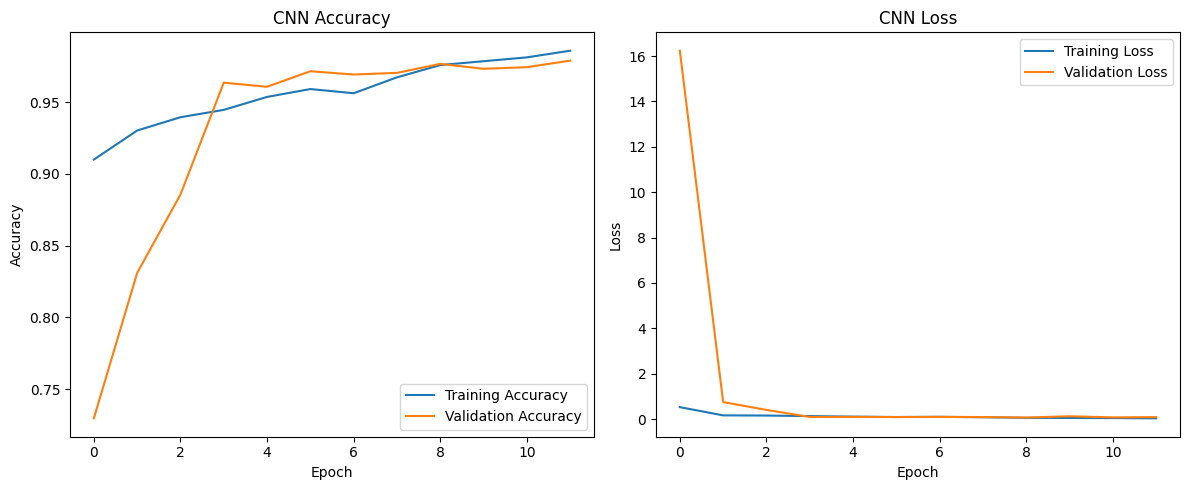

In [15]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [16]:
# Load best model
model = keras.models.load_model("best_cnn_model.keras")

# Evaluate
test_loss, test_accuracy, test_auc = model.evaluate(test_ds)

print("CNN Test Loss:", test_loss)
print("CNN Test Accuracy:", test_accuracy)
print("CNN Test AUROC:", test_auc)

55/55 ━━━━━━━━━━━━━━━━━━━━ 17s 300ms/step - accuracy: 0.9727 - auc: 0.9969 - loss: 0.0683
CNN Test Loss: 0.06828093528747559
CNN Test Accuracy: 0.9726806879043579
CNN Test AUROC: 0.9968692064285278


In [17]:
# Get predictions
cnn_prob = model.predict(test_ds).ravel()

cnn_pred = (cnn_prob >= 0.5).astype(int)

print("CNN Evaluation")
print("------------------------")

print("Accuracy:", accuracy_score(test_labels, cnn_pred))
print("Precision:", precision_score(test_labels, cnn_pred))
print("Recall:", recall_score(test_labels, cnn_pred))
print("F1 Score:", f1_score(test_labels, cnn_pred))
print("AUROC:", roc_auc_score(test_labels, cnn_prob))

print("\nClassification Report:")

print(classification_report(
    test_labels,
    cnn_pred,
    target_names=["NORMAL", "PNEUMONIA"]
))

55/55 ━━━━━━━━━━━━━━━━━━━━ 16s 276ms/step
CNN Evaluation
------------------------
Accuracy: 0.9726807057484348
Precision: 0.9865930599369085
Recall: 0.9758190327613104
F1 Score: 0.9811764705882353
AUROC: 0.997648411199606

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.94      0.96      0.95       475
   PNEUMONIA       0.99      0.98      0.98      1282

    accuracy                           0.97      1757
   macro avg       0.96      0.97      0.97      1757
weighted avg       0.97      0.97      0.97      1757



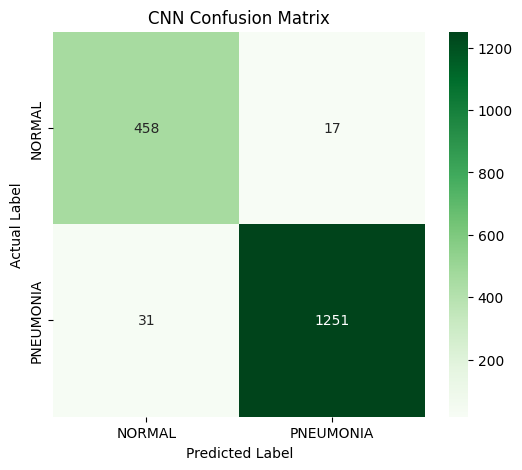

In [18]:
cm = confusion_matrix(test_labels, cnn_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("CNN Confusion Matrix")

plt.show()

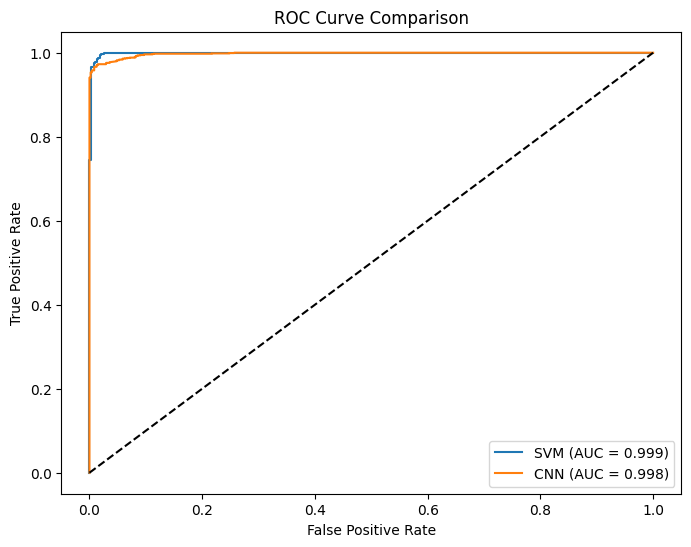

In [19]:
from sklearn.metrics import roc_curve, auc

# SVM ROC
fpr_svm, tpr_svm, _ = roc_curve(y_test, svm_prob)

# CNN ROC
fpr_cnn, tpr_cnn, _ = roc_curve(test_labels, cnn_prob)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_svm,
    tpr_svm,
    label=f"SVM (AUC = {auc(fpr_svm, tpr_svm):.3f})"
)

plt.plot(
    fpr_cnn,
    tpr_cnn,
    label=f"CNN (AUC = {auc(fpr_cnn, tpr_cnn):.3f})"
)

plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()
plt.show()

In [20]:
results = pd.DataFrame({

    "Model": ["SVM", "CNN"],

    "Accuracy": [
        accuracy_score(y_test, svm_pred),
        accuracy_score(test_labels, cnn_pred)
    ],

    "Precision": [
        precision_score(y_test, svm_pred),
        precision_score(test_labels, cnn_pred)
    ],

    "Recall": [
        recall_score(y_test, svm_pred),
        recall_score(test_labels, cnn_pred)
    ],

    "F1 Score": [
        f1_score(y_test, svm_pred),
        f1_score(test_labels, cnn_pred)
    ],

    "AUROC": [
        roc_auc_score(y_test, svm_prob),
        roc_auc_score(test_labels, cnn_prob)
    ]

})

print(results)

  Model  Accuracy  Precision    Recall  F1 Score     AUROC
0   SVM  0.990324   0.992218  0.994540  0.993377  0.998975
1   CNN  0.972681   0.986593  0.975819  0.981176  0.997648


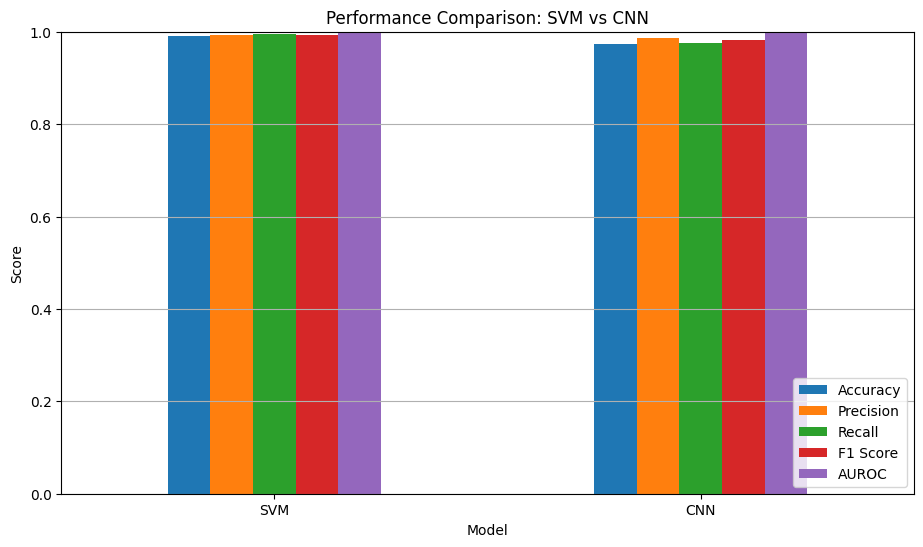

In [21]:
results.set_index("Model").plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Performance Comparison: SVM vs CNN")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.show()

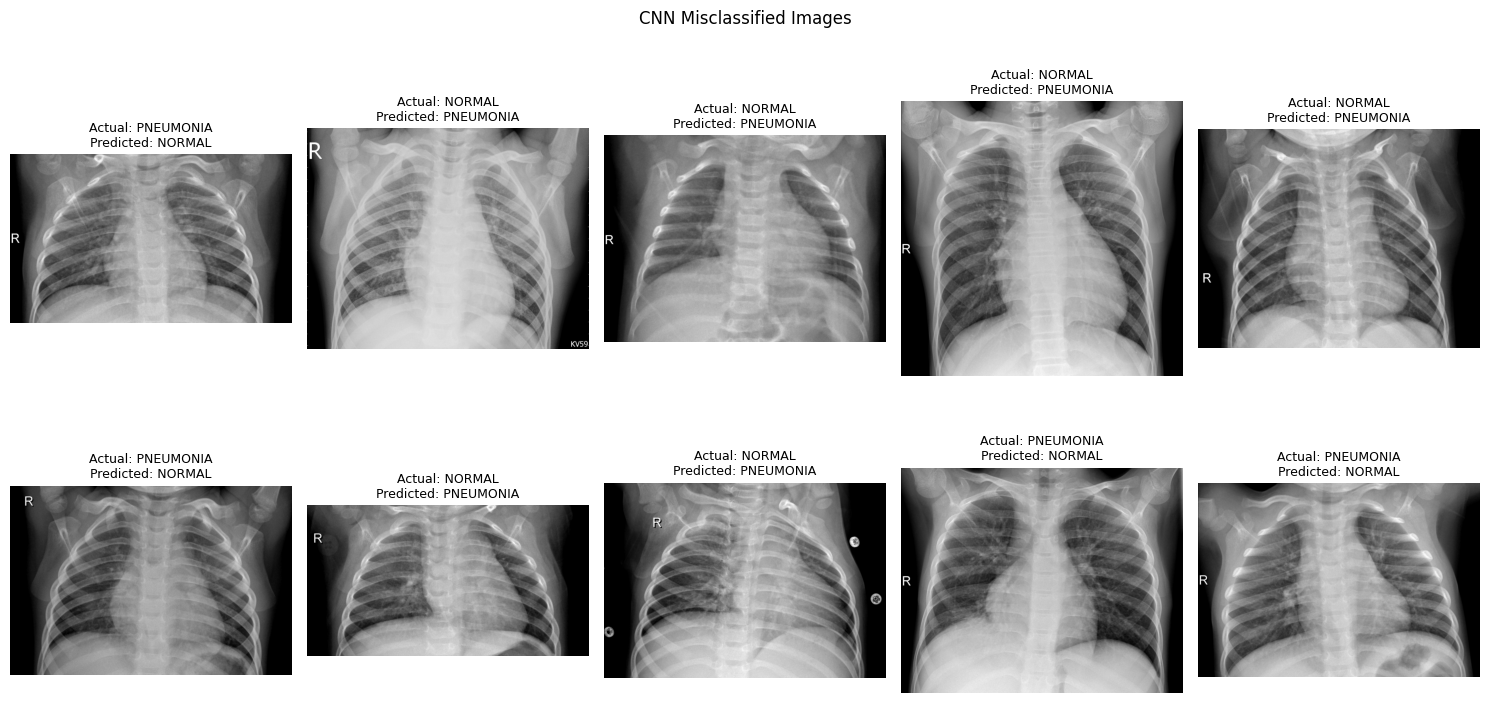

Total misclassified images: 48


In [22]:
misclassified = np.where(test_labels != cnn_pred)[0]

plt.figure(figsize=(15, 8))

for i, idx in enumerate(misclassified[:10]):

    img = cv2.imread(
        test_paths[idx],
        cv2.IMREAD_GRAYSCALE
    )

    plt.subplot(2, 5, i + 1)
    plt.imshow(img, cmap="gray")

    actual = "PNEUMONIA" if test_labels[idx] == 1 else "NORMAL"
    predicted = "PNEUMONIA" if cnn_pred[idx] == 1 else "NORMAL"

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        fontsize=9
    )

    plt.axis("off")

plt.suptitle("CNN Misclassified Images")
plt.tight_layout()
plt.show()

print("Total misclassified images:", len(misclassified))

In [23]:
model.save("Chest_Xray_CNN_Model.keras")

print("CNN model saved successfully!")

CNN model saved successfully!
